# Predicting Temperature with Weather Data

AI SCI 290A

Can other weather information improve my temperature model from notebook 02? I start by adding pressure and wind. Then I try averages of all the weather variables, nearby grid points, predicting the temperature change, and a small neural network. I also try predicting two or three days ahead and whether tomorrow will be hot.

I compare the models in three rounds from January to June 2010. I have already looked at July-December in earlier work, so I leave those dates out of these comparisons.

## 1. Find the files

In [1]:
# Import the same tools I used for temperature.
import glob
import xarray as xr

DATA_DIR = "C:/Users/giorg/Desktop/290A/Project1_WeatherPrediction/data/data"

In [2]:
# Find each kind of weather file.
pressure_files = sorted(glob.glob(f"{DATA_DIR}/**/mean_sea_level_pressure*.nc", recursive=True))
u_wind_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_u_component_of_wind*.nc", recursive=True))
v_wind_files = sorted(glob.glob(f"{DATA_DIR}/**/10m_v_component_of_wind*.nc", recursive=True))
precip_files = sorted(glob.glob(f"{DATA_DIR}/**/total_precipitation*.nc", recursive=True))

print("Pressure files:", len(pressure_files))
print("U wind files:", len(u_wind_files))
print("V wind files:", len(v_wind_files))
print("Precipitation files:", len(precip_files))

Pressure files: 12
U wind files: 12
V wind files: 12
Precipitation files: 12


## 2. Load pressure

This is mean sea-level pressure. I will check its units before changing anything.

In [3]:
# Open the files together, just like the temperature files.
ds_pressure = xr.open_mfdataset(pressure_files, combine="by_coords")

ds_pressure

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Data variables:
    msl         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:41 GRIB to CDM+CF via cfgrib-0.9.1...

In [4]:
# Check the variable name, units, and first and last dates.
print("Variables:", list(ds_pressure.data_vars))
print("Units:", ds_pressure["msl"].attrs.get("units"))
print("First date:", ds_pressure["valid_time"].values[0])
print("Last date:", ds_pressure["valid_time"].values[-1])

Variables: ['msl']
Units: Pa
First date: 2009-01-01T00:00:00.000000000
Last date: 2010-12-31T00:00:00.000000000


## 3. Load wind: u component

The u component describes east-west wind. It is not the total wind speed.

In [5]:
# Open the files together, just like the temperature files.
ds_u_wind = xr.open_mfdataset(u_wind_files, combine="by_coords")

ds_u_wind

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Data variables:
    u10         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:35 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
# Check the variable name, units, and first and last dates.
print("Variables:", list(ds_u_wind.data_vars))
print("Units:", ds_u_wind["u10"].attrs.get("units"))
print("First date:", ds_u_wind["valid_time"].values[0])
print("Last date:", ds_u_wind["valid_time"].values[-1])

Variables: ['u10']
Units: m s**-1
First date: 2009-01-01T00:00:00.000000000
Last date: 2010-12-31T00:00:00.000000000


## 4. Load wind: v component

The v component describes north-south wind. I will keep the two components separate for now.

In [7]:
# Open the files together, just like the temperature files.
ds_v_wind = xr.open_mfdataset(v_wind_files, combine="by_coords")

ds_v_wind

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Data variables:
    v10         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:37 GRIB to CDM+CF via cfgrib-0.9.1...

In [8]:
# Check the variable name, units, and first and last dates.
print("Variables:", list(ds_v_wind.data_vars))
print("Units:", ds_v_wind["v10"].attrs.get("units"))
print("First date:", ds_v_wind["valid_time"].values[0])
print("Last date:", ds_v_wind["valid_time"].values[-1])

Variables: ['v10']
Units: m s**-1
First date: 2009-01-01T00:00:00.000000000
Last date: 2010-12-31T00:00:00.000000000


## 5. Load precipitation

I load the precipitation files and look at their units and notes. I still need to check how the daily values were calculated before treating them as daily rainfall totals.

In [9]:
# Open the files together, just like the temperature files.
ds_precip = xr.open_mfdataset(precip_files, combine="by_coords")

ds_precip

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Data variables:
    tp          (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [10]:
# Check the variable name, units, and first and last dates.
print("Variables:", list(ds_precip.data_vars))
print("Units:", ds_precip["tp"].attrs.get("units"))
print("First date:", ds_precip["valid_time"].values[0])
print("Last date:", ds_precip["valid_time"].values[-1])

Variables: ['tp']
Units: m
First date: 2009-01-01T00:00:00.000000000
Last date: 2010-12-31T00:00:00.000000000


### Look at the precipitation notes

The units alone do not tell me whether this is a daily total or an average. I will also look at the notes stored with the data.

In [11]:
# Show the notes that came with the precipitation variable.
ds_precip["tp"].attrs

{'GRIB_paramId': np.int64(228),
 'GRIB_dataType': 'fc',
 'GRIB_numberOfPoints': np.int64(24885),
 'GRIB_typeOfLevel': 'surface',
 'GRIB_stepUnits': np.int64(1),
 'GRIB_stepType': 'accum',
 'GRIB_gridType': 'regular_ll',
 'GRIB_uvRelativeToGrid': np.int64(0),
 'GRIB_NV': np.int64(0),
 'GRIB_Nx': np.int64(237),
 'GRIB_Ny': np.int64(105),
 'GRIB_cfName': 'unknown',
 'GRIB_cfVarName': 'tp',
 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid',
 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_iScansNegatively': np.int64(0),
 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25),
 'GRIB_jPointsAreConsecutive': np.int64(0),
 'GRIB_jScansPositively': np.int64(0),
 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(50.0),
 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(24.0),
 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-125.0),
 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(-66.0),
 'GRIB_missingValue': np.float64(3.4028234663852886e+38),
 'GRIB_na

## 6. Plan for this notebook

I first look at pressure and wind, then check whether they help predict tomorrow's temperature. After that, I try a few more ideas from the project goals. I keep the same validation months so I can compare the results.

Predicting wind and precipitation themselves comes later in notebooks 04 and 05.

## 7. Look at pressure near Irvine

I will use the same grid point as in the temperature notebook.
First, I want to check the pressure values before adding them to my model.

In [12]:
pressure_irvine = ds_pressure["msl"].sel(
    latitude=33.75,
    longitude=-117.75,
    method="nearest"
)

In [13]:
pressure_irvine

<xarray.DataArray 'msl' (valid_time: 730)> Size: 3kB
dask.array<getitem, shape=(730,), dtype=float32, chunksize=(62,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             151
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               Pa
    long_name:                                Mean sea level pressure
    units:                                    Pa
    standard_name:                            air_pressure_at_mean_sea_level
    GRIB_surface:                             0.0

In [14]:
# Convert pressure from Pa to hPa.
pressure_hpa = pressure_irvine / 100
pressure_hpa.attrs["units"] = "hPa"

In [15]:
pressure_series = pressure_hpa.to_series()

In [16]:
print(pressure_series.head())
print("Missing values:", pressure_series.isna().sum())

valid_time
2009-01-01    1017.050415
2009-01-02    1014.690857
2009-01-03    1013.045654
2009-01-04    1014.790527
2009-01-05    1020.252808
Name: msl, dtype: float32
Missing values: 0


In [17]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Daily Mean Sea-Level Pressure Near Irvine, 2009–2010')

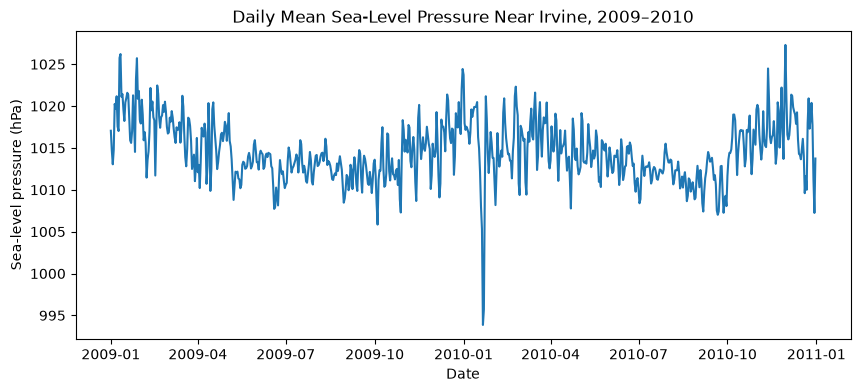

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(pressure_series.index, pressure_series)

ax.set_xlabel("Date")
ax.set_ylabel("Sea-level pressure (hPa)")
ax.set_title("Daily Mean Sea-Level Pressure Near Irvine, 2009–2010")

In [19]:
lowest_date = pressure_series.idxmin()

print("Lowest-pressure date:", lowest_date)
print("Pressure (hPa):", pressure_series.min())

pressure_series.loc["2010-01-01":"2010-01-31"]

Lowest-pressure date: 2010-01-21 00:00:00
Pressure (hPa): 993.8601


valid_time
2010-01-01    1023.721558
2010-01-02    1017.938416
2010-01-03    1017.152527
2010-01-04    1017.534607
2010-01-05    1017.228333
2010-01-06    1016.811279
2010-01-07    1015.490601
2010-01-08    1016.815247
2010-01-09    1019.596252
2010-01-10    1018.705688
2010-01-11    1019.397095
2010-01-12    1019.895630
2010-01-13    1019.875549
2010-01-14    1019.971863
2010-01-15    1020.474304
2010-01-16    1016.292725
2010-01-17    1014.952820
2010-01-18    1012.145630
2010-01-19    1008.001892
2010-01-20    1005.308228
2010-01-21     993.860107
2010-01-22     995.725403
2010-01-23    1010.550293
2010-01-24    1021.169739
2010-01-25    1018.479919
2010-01-26    1014.425537
2010-01-27    1012.003418
2010-01-28    1014.152893
2010-01-29    1016.899780
2010-01-30    1015.652161
2010-01-31    1013.825378
Name: msl, dtype: float32

Text(0.5, 1.0, 'Pressure Near Irvine, January 15–25, 2010')

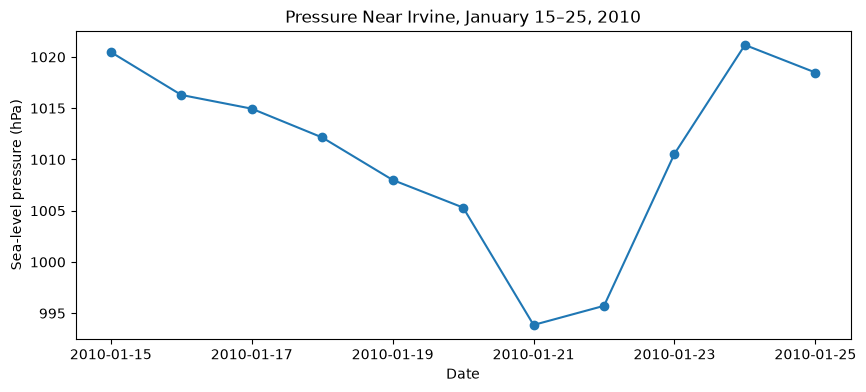

In [20]:
# Zoom in on the days around the lowest pressure， which seems a little extreme to me.
pressure_jan = pressure_series.loc["2010-01-15":"2010-01-25"]

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(pressure_jan.index, pressure_jan, marker="o")

ax.set_xlabel("Date")
ax.set_ylabel("Sea-level pressure (hPa)")
ax.set_title("Pressure Near Irvine, January 15–25, 2010")

The pressure dip looks less strange when I zoom in: it drops over several days and then rises again. I keep it for now, but I have not checked weather records to explain it.

## 8. Make the daily table

I put the weather values from the same day on one row. Then I add the temperature averages and tomorrow's actual temperature, as I did in notebook 02.

In [21]:
# Find and open the temperature files.
temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/2m_temperature*.nc", recursive=True)
)
ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")

temp_irvine = ds_temp["t2m"].sel(
    latitude=33.75,
    longitude=-117.75,
    method="nearest"
) - 273.15

# Put temperature into a Series with dates as the index.
temp_series = temp_irvine.to_series()

In [22]:
print(temp_series.head())
print("Same dates:", temp_series.index.equals(pressure_series.index))

valid_time
2009-01-01    10.976807
2009-01-02    10.043762
2009-01-03    10.752289
2009-01-04    10.557648
2009-01-05     7.683075
Name: t2m, dtype: float32
Same dates: True


In [23]:
# Put temperature and pressure into one table.
import pandas as pd

df_weather = pd.DataFrame({
    "today_temp": temp_series,
    "pressure_hpa": pressure_series
})

In [24]:
print(df_weather.head())
print("Missing values:")
print(df_weather.isna().sum())

            today_temp  pressure_hpa
valid_time                          
2009-01-01   10.976807   1017.050415
2009-01-02   10.043762   1014.690857
2009-01-03   10.752289   1013.045654
2009-01-04   10.557648   1014.790527
2009-01-05    7.683075   1020.252808
Missing values:
today_temp      0
pressure_hpa    0
dtype: int64


In [25]:
df_weather["temp_3day"] = df_weather["today_temp"].rolling(3).mean()
df_weather["temp_7day"] = df_weather["today_temp"].rolling(7).mean()

df_weather["tomorrow_temp"] = df_weather["today_temp"].shift(-1)
df_weather["target_date"] = df_weather.index + pd.Timedelta(days=1)

df_weather_model = df_weather.dropna(
    subset=["today_temp", "pressure_hpa", "temp_3day",
            "temp_7day", "tomorrow_temp"]
).copy()

In [26]:
print("Rows for modeling:", len(df_weather_model))
df_weather_model.head()

Rows for modeling: 723


,today_temp,pressure_hpa,temp_3day,temp_7day,tomorrow_temp,target_date
valid_time,,,,,,
2009-01-07,10.581696,1021.168518,9.166158,9.975568,11.220703,2009-01-08
2009-01-08,11.220703,1017.560364,10.345367,10.010411,12.512634,2009-01-09
2009-01-09,12.512634,1017.018799,11.438344,10.363107,12.194153,2009-01-10
2009-01-10,12.194153,1025.754639,11.975830,10.569087,13.224915,2009-01-11
2009-01-11,13.224915,1026.206543,12.643901,10.950126,16.540802,2009-01-12


## 9. Does pressure help?

### Round 1: January-February

In [27]:
# Use target dates in 2009 for training.
train_1 = df_weather_model[
    df_weather_model["target_date"] < "2010-01-01"
].copy()

# Use January-February 2010 target dates for validation.
val_1 = df_weather_model[
    (df_weather_model["target_date"] >= "2010-01-01") &
    (df_weather_model["target_date"] < "2010-03-01")
].copy()

In [28]:
print("Training rows:", len(train_1))
print("Validation rows:", len(val_1))

Training rows: 358
Validation rows: 59


In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
# Compare temperature inputs with and without today's pressure.
temp_features = ["today_temp", "temp_3day", "temp_7day"]
pressure_features = temp_features + ["pressure_hpa"]

In [31]:
# Train both models on the same rows.
reg_temp_1 = LinearRegression()
reg_temp_1.fit(train_1[temp_features], train_1["tomorrow_temp"])

reg_pressure_1 = LinearRegression()
reg_pressure_1.fit(train_1[pressure_features], train_1["tomorrow_temp"])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 1.3 ,-0.62, 0.33, 0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['today_temp','temp_3day','temp_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-102.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [32]:
val_1["temp_pred"] = reg_temp_1.predict(val_1[temp_features])
val_1["pressure_pred"] = reg_pressure_1.predict(val_1[pressure_features])

In [33]:
# Calculate errors for both models.
temp_errors_1 = val_1["temp_pred"] - val_1["tomorrow_temp"]
pressure_errors_1 = val_1["pressure_pred"] - val_1["tomorrow_temp"]

In [34]:
# Put MAE and RMSE into a comparison table.
results_1 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + pressure"],
    "MAE": [
        temp_errors_1.abs().mean(),
        pressure_errors_1.abs().mean()
    ],
    "RMSE": [
        ((temp_errors_1 ** 2).mean()) ** 0.5,
        ((pressure_errors_1 ** 2).mean()) ** 0.5
    ]
})

In [35]:
results_1.round(4)

,Model,MAE,RMSE
0,Temperature only,0.8149,1.0593
1,Temperature + pressure,0.7928,1.0287


In [36]:
pressure_results = results_1.copy()
pressure_results["Period"] = "Jan-Feb 2010"

temp_error_list = [temp_errors_1]
pressure_error_list = [pressure_errors_1]

### Round 2: March-April

In [37]:
# Then, use target dates before March 2010 for training.
train_2 = df_weather_model[
    df_weather_model["target_date"] < "2010-03-01"
].copy()

In [38]:
val_2 = df_weather_model[
    (df_weather_model["target_date"] >= "2010-03-01") &
    (df_weather_model["target_date"] < "2010-05-01")
].copy()

In [39]:
reg_temp_2 = LinearRegression()
reg_temp_2.fit(
    train_2[temp_features],
    train_2["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 1.35,-0.67, 0.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['today_temp','temp_3day','temp_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.5896
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [40]:
reg_pressure_2 = LinearRegression()
reg_pressure_2.fit(
    train_2[pressure_features],
    train_2["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 1.3 ,-0.62, 0.32, 0.08]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['today_temp','temp_3day','temp_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-84.35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [41]:
val_2["temp_pred"] = reg_temp_2.predict(val_2[temp_features])
val_2["pressure_pred"] = reg_pressure_2.predict(val_2[pressure_features])

In [42]:
# Compare the real temperatures with both predictions.
val_2[["tomorrow_temp", "temp_pred", "pressure_pred"]].head()

,tomorrow_temp,temp_pred,pressure_pred
valid_time,,,
2010-02-28,12.905334,10.223507,9.745761
2010-03-01,13.599060,13.246274,13.333605
2010-03-02,13.159821,14.326536,14.355785
2010-03-03,11.712189,13.252477,13.280937
2010-03-04,11.591949,11.493691,11.503046


In [43]:
temp_errors_2 = val_2["temp_pred"] - val_2["tomorrow_temp"]
pressure_errors_2 = val_2["pressure_pred"] - val_2["tomorrow_temp"]

In [44]:
# Compare MAE and RMSE for March-April.
results_2 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + pressure"],
    "MAE": [
        temp_errors_2.abs().mean(),
        pressure_errors_2.abs().mean()
    ],
    "RMSE": [
        ((temp_errors_2 ** 2).mean()) ** 0.5,
        ((pressure_errors_2 ** 2).mean()) ** 0.5
    ]
})

results_2.round(4)

,Model,MAE,RMSE
0,Temperature only,0.9882,1.2643
1,Temperature + pressure,0.9997,1.2868


### Round 2: Does pressure help?

Adding pressure makes both errors a little higher in March-April: MAE goes from 0.9882 to 0.9997 C, and RMSE from 1.2643 to 1.2868 C. It helped in the first round, but not this one.

### Round 3: May-June

In [45]:
train_3 = df_weather_model[
    df_weather_model["target_date"] < "2010-05-01"
].copy()

In [46]:
val_3 = df_weather_model[
    (df_weather_model["target_date"] >= "2010-05-01") &
    (df_weather_model["target_date"] < "2010-07-01")
].copy()

In [47]:
reg_temp_3 = LinearRegression()
reg_temp_3.fit(
    train_3[temp_features],
    train_3["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 1.32,-0.66, 0.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['today_temp','temp_3day','temp_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6595
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [48]:
reg_pressure_3 = LinearRegression()
reg_pressure_3.fit(
    train_3[pressure_features],
    train_3["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 1.27,-0.6 , 0.32, 0.08]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['today_temp','temp_3day','temp_7day','pressure_hpa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-76.49
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [49]:
val_3["temp_pred"] = reg_temp_3.predict(val_3[temp_features])
val_3["pressure_pred"] = reg_pressure_3.predict(val_3[pressure_features])
val_3[["tomorrow_temp", "temp_pred", "pressure_pred"]].head()

,tomorrow_temp,temp_pred,pressure_pred
valid_time,,,
2010-04-30,14.937927,14.254765,13.968920
2010-05-01,15.324524,15.494989,15.190423
2010-05-02,16.744781,15.541266,15.307615
2010-05-03,17.558014,16.858180,17.099027
2010-05-04,16.802185,17.476784,17.670313


In [50]:
temp_errors_3 = val_3["temp_pred"] - val_3["tomorrow_temp"]
pressure_errors_3 = val_3["pressure_pred"] - val_3["tomorrow_temp"]

In [51]:
# Compare MAE and RMSE for May-June.
results_3 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + pressure"],
    "MAE": [
        temp_errors_3.abs().mean(),
        pressure_errors_3.abs().mean()
    ],
    "RMSE": [
        ((temp_errors_3 ** 2).mean()) ** 0.5,
        ((pressure_errors_3 ** 2).mean()) ** 0.5
    ]
})

results_3.round(4)

,Model,MAE,RMSE
0,Temperature only,0.6651,0.8618
1,Temperature + pressure,0.6779,0.8511


### Round 3: Mixed results

In May-June, pressure makes MAE slightly worse (0.6651 to 0.6779 C), but RMSE slightly better (0.8618 to 0.8511 C). It is a mixed result.

In [52]:
# Join the daily errors from all three validation periods.
temp_errors_all = pd.concat([
    temp_errors_1, temp_errors_2, temp_errors_3
])

pressure_errors_all = pd.concat([
    pressure_errors_1, pressure_errors_2, pressure_errors_3
])

# Calculate overall scores, giving each validation day equal weight.
overall_results = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + pressure"],
    "MAE": [
        temp_errors_all.abs().mean(),
        pressure_errors_all.abs().mean()
    ],
    "RMSE": [
        ((temp_errors_all ** 2).mean()) ** 0.5,
        ((pressure_errors_all ** 2).mean()) ** 0.5
    ]
})

overall_results.round(4)

,Model,MAE,RMSE
0,Temperature only,0.8228,1.0746
1,Temperature + pressure,0.8238,1.0711


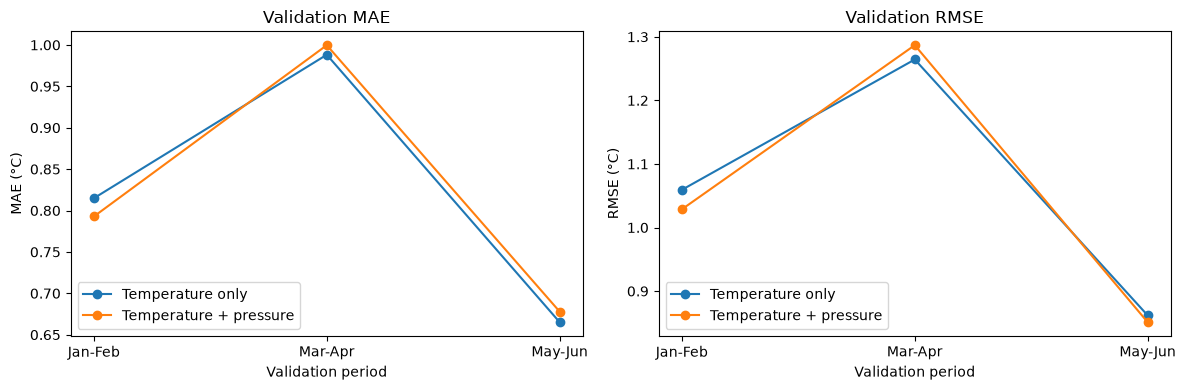

In [53]:
periods = ["Jan-Feb", "Mar-Apr", "May-Jun"]

temp_mae = [results_1.loc[0, "MAE"],
            results_2.loc[0, "MAE"],
            results_3.loc[0, "MAE"]]

pressure_mae = [results_1.loc[1, "MAE"],
                results_2.loc[1, "MAE"],
                results_3.loc[1, "MAE"]]

temp_rmse = [results_1.loc[0, "RMSE"],
             results_2.loc[0, "RMSE"],
             results_3.loc[0, "RMSE"]]

pressure_rmse = [results_1.loc[1, "RMSE"],
                 results_2.loc[1, "RMSE"],
                 results_3.loc[1, "RMSE"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(periods, temp_mae, marker="o", label="Temperature only")
axes[0].plot(periods, pressure_mae, marker="o", label="Temperature + pressure")
axes[0].set_xlabel("Validation period")
axes[0].set_ylabel("MAE (°C)")
axes[0].set_title("Validation MAE")
axes[0].legend()

axes[1].plot(periods, temp_rmse, marker="o", label="Temperature only")
axes[1].plot(periods, pressure_rmse, marker="o", label="Temperature + pressure")
axes[1].set_xlabel("Validation period")
axes[1].set_ylabel("RMSE (°C)")
axes[1].set_title("Validation RMSE")
axes[1].legend()

fig.tight_layout()

### Overall: Does pressure improve the model?

Overall, pressure barely changes the scores: MAE goes from 0.8228 to 0.8238 C and RMSE from 1.0746 to 1.0711 C. I do not see a clear improvement, so I try wind next.

## 10. Does wind help?

I add today's average u and v values to the temperature model. I want to see whether knowing the wind helps predict tomorrow's temperature.

### Prepare the wind data

In [54]:
u_irvine = ds_u_wind["u10"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
).to_series()

v_irvine = ds_v_wind["v10"].sel(
    latitude=33.75, longitude=-117.75, method="nearest"
).to_series()

In [55]:
df_weather["u10"] = u_irvine
df_weather["v10"] = v_irvine

print(df_weather[["u10", "v10"]].head())
print("Missing values:")
print(df_weather[["u10", "v10"]].isna().sum())

                 u10       v10
valid_time                    
2009-01-01 -0.581250  0.012833
2009-01-02 -0.532312  0.843110
2009-01-03 -0.766132  1.317292
2009-01-04 -0.897218 -0.563737
2009-01-05 -0.796495 -0.120888
Missing values:
u10    0
v10    0
dtype: int64


In [56]:
# Keep rows with all other inputs.
df_wind_model = df_weather.dropna(
    subset=["today_temp", "temp_3day", "temp_7day",
            "u10", "v10", "tomorrow_temp"]
).copy()

In [57]:
wind_features = temp_features + ["u10", "v10"]

### Round 1: January-February

In [58]:
train_wind_1 = df_wind_model[
    df_wind_model["target_date"] < "2010-01-01"
].copy()

In [59]:
val_wind_1 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-01-01") &
    (df_wind_model["target_date"] < "2010-03-01")
].copy()

In [60]:
val_wind_1.index.equals(val_1.index)

True

In [61]:
# Train.
reg_temp_wind_1 = LinearRegression()
reg_temp_wind_1.fit(
    train_wind_1[temp_features], train_wind_1["tomorrow_temp"]
)

reg_wind_1 = LinearRegression()
reg_wind_1.fit(
    train_wind_1[wind_features], train_wind_1["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 1.32,-0.66, 0.31, 0.02,-0.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['today_temp','temp_3day','temp_7day','u10','v10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.6118
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [62]:
# Predict.
val_wind_1["temp_pred"] = reg_temp_wind_1.predict(
    val_wind_1[temp_features]
)
val_wind_1["wind_pred"] = reg_wind_1.predict(
    val_wind_1[wind_features]
)


In [63]:
# Calculate.
temp_wind_errors_1 = (
    val_wind_1["temp_pred"] - val_wind_1["tomorrow_temp"]
)
wind_errors_1 = (
    val_wind_1["wind_pred"] - val_wind_1["tomorrow_temp"]
)

In [64]:
# Compare.
wind_results_1 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + wind"],
    "MAE": [
        temp_wind_errors_1.abs().mean(),
        wind_errors_1.abs().mean()
    ],
    "RMSE": [
        ((temp_wind_errors_1 ** 2).mean()) ** 0.5,
        ((wind_errors_1 ** 2).mean()) ** 0.5
    ]
})

wind_results_1.round(4)

,Model,MAE,RMSE
0,Temperature only,0.8149,1.0593
1,Temperature + wind,0.7763,1.0135


### Round 2: March-April

In [65]:
train_wind_2 = df_wind_model[
    df_wind_model["target_date"] < "2010-03-01"
].copy()

val_wind_2 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-03-01") &
    (df_wind_model["target_date"] < "2010-05-01")
].copy()

In [66]:
reg_temp_wind_2 = LinearRegression()
reg_temp_wind_2.fit(
    train_wind_2[temp_features],
    train_wind_2["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 1.35,-0.67, 0.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['today_temp','temp_3day','temp_7day']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.5896
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [67]:
reg_wind_2 = LinearRegression()
reg_wind_2.fit(
    train_wind_2[wind_features],
    train_wind_2["tomorrow_temp"]
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 1.3 ,-0.64, 0.31, 0.03,-0.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['today_temp','temp_3day','temp_7day','u10','v10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.5359
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [68]:
val_wind_2["temp_pred"] = reg_temp_wind_2.predict(
    val_wind_2[temp_features]
)
val_wind_2["wind_pred"] = reg_wind_2.predict(
    val_wind_2[wind_features]
)

In [69]:
val_wind_2[["tomorrow_temp", "temp_pred", "wind_pred"]].head()

,tomorrow_temp,temp_pred,wind_pred
valid_time,,,
2010-02-28,12.905334,10.223507,10.264085
2010-03-01,13.599060,13.246274,13.209180
2010-03-02,13.159821,14.326536,14.255424
2010-03-03,11.712189,13.252477,13.254733
2010-03-04,11.591949,11.493691,11.616986


In [70]:
temp_wind_errors_2 = (
    val_wind_2["temp_pred"] - val_wind_2["tomorrow_temp"]
)
wind_errors_2 = (
    val_wind_2["wind_pred"] - val_wind_2["tomorrow_temp"]
)

In [71]:
wind_results_2 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + wind"],
    "MAE": [
        temp_wind_errors_2.abs().mean(),
        wind_errors_2.abs().mean()
    ],
    "RMSE": [
        ((temp_wind_errors_2 ** 2).mean()) ** 0.5,
        ((wind_errors_2 ** 2).mean()) ** 0.5
    ]
})

wind_results_2.round(4)

,Model,MAE,RMSE
0,Temperature only,0.9882,1.2643
1,Temperature + wind,0.9670,1.2359


### Round 3: May-June

In [72]:
train_wind_3 = df_wind_model[
    df_wind_model["target_date"] < "2010-05-01"
].copy()

val_wind_3 = df_wind_model[
    (df_wind_model["target_date"] >= "2010-05-01") &
    (df_wind_model["target_date"] < "2010-07-01")
].copy()

reg_temp_wind_3 = LinearRegression()
reg_temp_wind_3.fit(
    train_wind_3[temp_features], train_wind_3["tomorrow_temp"]
)

reg_wind_3 = LinearRegression()
reg_wind_3.fit(
    train_wind_3[wind_features], train_wind_3["tomorrow_temp"]
)

val_wind_3["temp_pred"] = reg_temp_wind_3.predict(
    val_wind_3[temp_features]
)
val_wind_3["wind_pred"] = reg_wind_3.predict(
    val_wind_3[wind_features]
)

val_wind_3[["tomorrow_temp", "temp_pred", "wind_pred"]].head()

,tomorrow_temp,temp_pred,wind_pred
valid_time,,,
2010-04-30,14.937927,14.254765,14.433694
2010-05-01,15.324524,15.494989,15.214364
2010-05-02,16.744781,15.541266,15.049024
2010-05-03,17.558014,16.858180,16.751483
2010-05-04,16.802185,17.476784,17.295199


In [73]:
temp_wind_errors_3 = (
    val_wind_3["temp_pred"] - val_wind_3["tomorrow_temp"]
)
wind_errors_3 = (
    val_wind_3["wind_pred"] - val_wind_3["tomorrow_temp"]
)

In [74]:
wind_results_3 = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + wind"],
    "MAE": [
        temp_wind_errors_3.abs().mean(),
        wind_errors_3.abs().mean()
    ],
    "RMSE": [
        ((temp_wind_errors_3 ** 2).mean()) ** 0.5,
        ((wind_errors_3 ** 2).mean()) ** 0.5
    ]
})

wind_results_3.round(4)

,Model,MAE,RMSE
0,Temperature only,0.6651,0.8618
1,Temperature + wind,0.6961,0.8682


### Round 3: Wind did not help in this period

Wind makes both scores worse in May-June: MAE goes from 0.6651 to 0.6961 C and RMSE from 0.8618 to 0.8682 C. It helped in the first two rounds, but not the third.

In [75]:
temp_wind_errors_all = pd.concat([
    temp_wind_errors_1, temp_wind_errors_2, temp_wind_errors_3
])

wind_errors_all = pd.concat([
    wind_errors_1, wind_errors_2, wind_errors_3
])

wind_overall_results = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + wind"],
    "MAE": [
        temp_wind_errors_all.abs().mean(),
        wind_errors_all.abs().mean()
    ],
    "RMSE": [
        ((temp_wind_errors_all ** 2).mean()) ** 0.5,
        ((wind_errors_all ** 2).mean()) ** 0.5
    ]
})

wind_overall_results.round(4)

,Model,MAE,RMSE
0,Temperature only,0.8228,1.0746
1,Temperature + wind,0.8135,1.0505


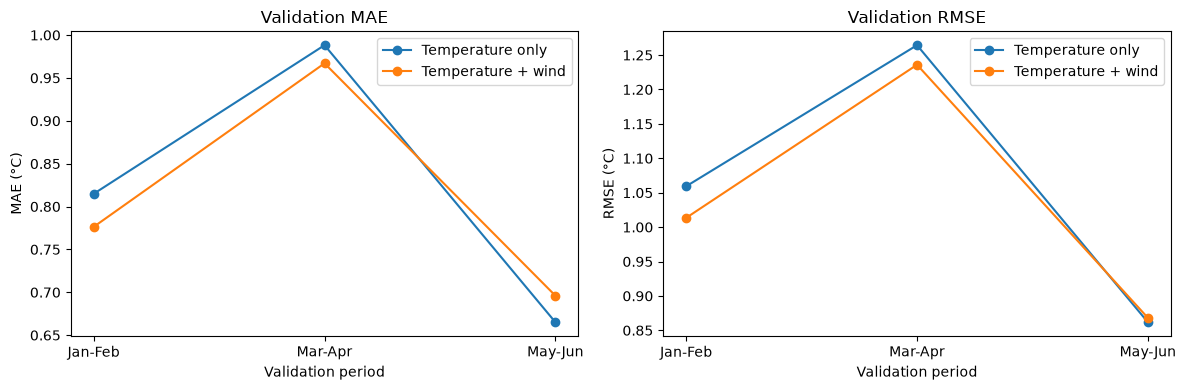

In [76]:
periods = ["Jan-Feb", "Mar-Apr", "May-Jun"]

temp_mae = [wind_results_1.loc[0, "MAE"],
            wind_results_2.loc[0, "MAE"],
            wind_results_3.loc[0, "MAE"]]

wind_mae = [wind_results_1.loc[1, "MAE"],
            wind_results_2.loc[1, "MAE"],
            wind_results_3.loc[1, "MAE"]]

temp_rmse = [wind_results_1.loc[0, "RMSE"],
             wind_results_2.loc[0, "RMSE"],
             wind_results_3.loc[0, "RMSE"]]

wind_rmse = [wind_results_1.loc[1, "RMSE"],
             wind_results_2.loc[1, "RMSE"],
             wind_results_3.loc[1, "RMSE"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(periods, temp_mae, marker="o", label="Temperature only")
axes[0].plot(periods, wind_mae, marker="o", label="Temperature + wind")
axes[0].set_xlabel("Validation period")
axes[0].set_ylabel("MAE (°C)")
axes[0].set_title("Validation MAE")
axes[0].legend()

axes[1].plot(periods, temp_rmse, marker="o", label="Temperature only")
axes[1].plot(periods, wind_rmse, marker="o", label="Temperature + wind")
axes[1].set_xlabel("Validation period")
axes[1].set_ylabel("RMSE (°C)")
axes[1].set_title("Validation RMSE")
axes[1].legend()

fig.tight_layout()

### Overall: Does wind improve the model?

Adding wind lowers overall MAE from 0.8228 to 0.8135 C and RMSE from 1.0746 to 1.0505 C. It is a small improvement, and it does not happen in every round.

## 11. Try wind and pressure together

I try pressure and wind together as one more comparison. The temperature inputs stay the same: today's temperature and its 3-day and 7-day averages.

In [77]:
combined_features = temp_features + ["u10", "v10", "pressure_hpa"]
df_combined = df_weather.dropna(
    subset=combined_features + ["tomorrow_temp", "target_date"]
).copy()

print("Rows:", len(df_combined))
print("Same rows as pressure experiment:", df_combined.index.equals(df_weather_model.index))
print("Same rows as wind experiment:", df_combined.index.equals(df_wind_model.index))

Rows: 723
Same rows as pressure experiment: True
Same rows as wind experiment: True


### Round 1: January-February

In [78]:
train_combined_1 = df_combined[df_combined["target_date"] < "2010-01-01"].copy()
val_combined_1 = df_combined[
    (df_combined["target_date"] >= "2010-01-01") &
    (df_combined["target_date"] < "2010-03-01")
].copy()

print("Training rows:", len(train_combined_1))
print("Validation rows:", len(val_combined_1))
print("Same validation dates:", val_combined_1.index.equals(val_wind_1.index))

Training rows: 358
Validation rows: 59
Same validation dates: True


In [79]:
reg_combined_1 = LinearRegression()
reg_combined_1.fit(
    train_combined_1[combined_features], train_combined_1["tomorrow_temp"]
)

val_combined_1["combined_pred"] = reg_combined_1.predict(
    val_combined_1[combined_features]
)
combined_errors_1 = (
    val_combined_1["combined_pred"] - val_combined_1["tomorrow_temp"]
)

In [80]:
# Compare adding pressure with keeping temperature and wind alone.
combined_results_1 = pd.DataFrame({
    "Model": ["Temperature + wind", "Temperature + wind + pressure"],
    "MAE": [wind_errors_1.abs().mean(), combined_errors_1.abs().mean()],
    "RMSE": [
        ((wind_errors_1 ** 2).mean()) ** 0.5,
        ((combined_errors_1 ** 2).mean()) ** 0.5
    ]
})
combined_results_1.round(4)

,Model,MAE,RMSE
0,Temperature + wind,0.7763,1.0135
1,Temperature + wind + pressure,0.7820,1.0207


### Round 2: March-April

In [81]:
train_combined_2 = df_combined[df_combined["target_date"] < "2010-03-01"].copy()
val_combined_2 = df_combined[
    (df_combined["target_date"] >= "2010-03-01") &
    (df_combined["target_date"] < "2010-05-01")
].copy()

print("Training rows:", len(train_combined_2))
print("Validation rows:", len(val_combined_2))
print("Same validation dates:", val_combined_2.index.equals(val_wind_2.index))

Training rows: 417
Validation rows: 61
Same validation dates: True


In [82]:
reg_combined_2 = LinearRegression()
reg_combined_2.fit(
    train_combined_2[combined_features], train_combined_2["tomorrow_temp"]
)

val_combined_2["combined_pred"] = reg_combined_2.predict(
    val_combined_2[combined_features]
)
combined_errors_2 = (
    val_combined_2["combined_pred"] - val_combined_2["tomorrow_temp"]
)

In [83]:
combined_results_2 = pd.DataFrame({
    "Model": ["Temperature + wind", "Temperature + wind + pressure"],
    "MAE": [wind_errors_2.abs().mean(), combined_errors_2.abs().mean()],
    "RMSE": [
        ((wind_errors_2 ** 2).mean()) ** 0.5,
        ((combined_errors_2 ** 2).mean()) ** 0.5
    ]
})
combined_results_2.round(4)

,Model,MAE,RMSE
0,Temperature + wind,0.9670,1.2359
1,Temperature + wind + pressure,0.9866,1.2717


### Round 3: May-June

In [84]:
train_combined_3 = df_combined[df_combined["target_date"] < "2010-05-01"].copy()
val_combined_3 = df_combined[
    (df_combined["target_date"] >= "2010-05-01") &
    (df_combined["target_date"] < "2010-07-01")
].copy()

print("Training rows:", len(train_combined_3))
print("Validation rows:", len(val_combined_3))
print("Same validation dates:", val_combined_3.index.equals(val_wind_3.index))

Training rows: 478
Validation rows: 61
Same validation dates: True


In [85]:
# Train with temperature, wind, and pressure.
reg_combined_3 = LinearRegression()
reg_combined_3.fit(
    train_combined_3[combined_features], train_combined_3["tomorrow_temp"]
)

val_combined_3["combined_pred"] = reg_combined_3.predict(
    val_combined_3[combined_features]
)
combined_errors_3 = (
    val_combined_3["combined_pred"] - val_combined_3["tomorrow_temp"]
)

In [86]:
combined_results_3 = pd.DataFrame({
    "Model": ["Temperature + wind", "Temperature + wind + pressure"],
    "MAE": [wind_errors_3.abs().mean(), combined_errors_3.abs().mean()],
    "RMSE": [
        ((wind_errors_3 ** 2).mean()) ** 0.5,
        ((combined_errors_3 ** 2).mean()) ** 0.5
    ]
})
combined_results_3.round(4)

,Model,MAE,RMSE
0,Temperature + wind,0.6961,0.8682
1,Temperature + wind + pressure,0.6844,0.8545


### What happened in the three rounds?

Adding pressure to the wind model makes both scores worse in the first two rounds and better in the third. It does not help consistently.

## 12. Compare all four models

I put the daily errors together and calculate the scores across all 181 validation days.

In [87]:
combined_errors_all = pd.concat([
    combined_errors_1, combined_errors_2, combined_errors_3
])

print("Validation days:", len(combined_errors_all))
print("Dates match:",
      combined_errors_all.index.equals(temp_errors_all.index) and
      combined_errors_all.index.equals(pressure_errors_all.index) and
      combined_errors_all.index.equals(wind_errors_all.index))

model_comparison = pd.DataFrame({
    "Model": ["Temperature only", "Temperature + pressure",
              "Temperature + wind", "Temperature + wind + pressure"],
    "MAE": [temp_errors_all.abs().mean(), pressure_errors_all.abs().mean(),
            wind_errors_all.abs().mean(), combined_errors_all.abs().mean()],
    "RMSE": [((temp_errors_all ** 2).mean()) ** 0.5,
             ((pressure_errors_all ** 2).mean()) ** 0.5,
             ((wind_errors_all ** 2).mean()) ** 0.5,
             ((combined_errors_all ** 2).mean()) ** 0.5]
})
model_comparison.round(4)

Validation days: 181
Dates match: True


,Model,MAE,RMSE
0,Temperature only,0.8228,1.0746
1,Temperature + pressure,0.8238,1.0711
2,Temperature + wind,0.8135,1.0505
3,Temperature + wind + pressure,0.8180,1.0634


In [88]:
# Put the scores for each period into two small tables.
mae_by_period = pd.DataFrame({
    "Temperature only": [results_1.loc[0, "MAE"], results_2.loc[0, "MAE"], results_3.loc[0, "MAE"]],
    "Temperature + pressure": [results_1.loc[1, "MAE"], results_2.loc[1, "MAE"], results_3.loc[1, "MAE"]],
    "Temperature + wind": [wind_results_1.loc[1, "MAE"], wind_results_2.loc[1, "MAE"], wind_results_3.loc[1, "MAE"]],
    "Temperature + wind + pressure": [combined_results_1.loc[1, "MAE"], combined_results_2.loc[1, "MAE"], combined_results_3.loc[1, "MAE"]]
}, index=periods)

rmse_by_period = pd.DataFrame({
    "Temperature only": [results_1.loc[0, "RMSE"], results_2.loc[0, "RMSE"], results_3.loc[0, "RMSE"]],
    "Temperature + pressure": [results_1.loc[1, "RMSE"], results_2.loc[1, "RMSE"], results_3.loc[1, "RMSE"]],
    "Temperature + wind": [wind_results_1.loc[1, "RMSE"], wind_results_2.loc[1, "RMSE"], wind_results_3.loc[1, "RMSE"]],
    "Temperature + wind + pressure": [combined_results_1.loc[1, "RMSE"], combined_results_2.loc[1, "RMSE"], combined_results_3.loc[1, "RMSE"]]
}, index=periods)

mae_by_period.round(4)

,Temperature only,Temperature + pressure,Temperature + wind,Temperature + wind + pressure
Jan-Feb,0.8149,0.7928,0.7763,0.7820
Mar-Apr,0.9882,0.9997,0.9670,0.9866
May-Jun,0.6651,0.6779,0.6961,0.6844


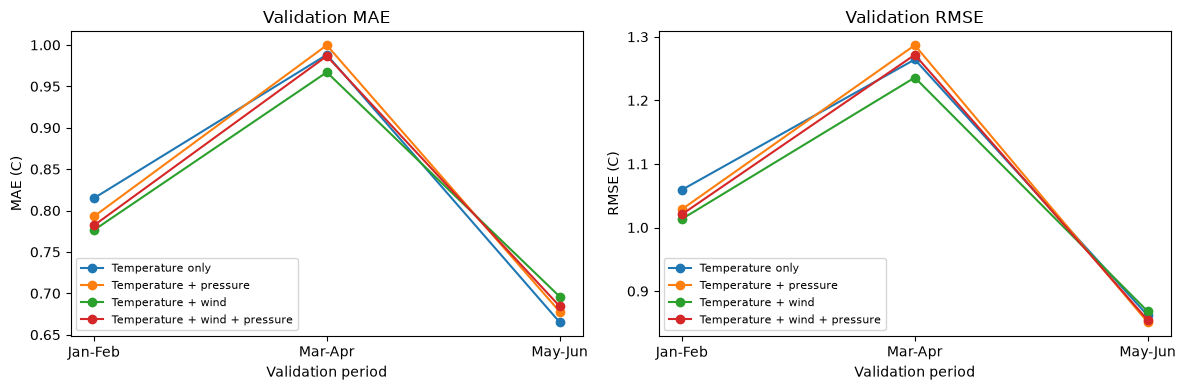

In [89]:
# Plot all four models over the same three validation periods.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(periods, mae_by_period["Temperature only"], marker="o", label="Temperature only")
axes[0].plot(periods, mae_by_period["Temperature + pressure"], marker="o", label="Temperature + pressure")
axes[0].plot(periods, mae_by_period["Temperature + wind"], marker="o", label="Temperature + wind")
axes[0].plot(periods, mae_by_period["Temperature + wind + pressure"], marker="o", label="Temperature + wind + pressure")
axes[0].set_xlabel("Validation period")
axes[0].set_ylabel("MAE (C)")
axes[0].set_title("Validation MAE")
axes[0].legend(fontsize=8)

axes[1].plot(periods, rmse_by_period["Temperature only"], marker="o", label="Temperature only")
axes[1].plot(periods, rmse_by_period["Temperature + pressure"], marker="o", label="Temperature + pressure")
axes[1].plot(periods, rmse_by_period["Temperature + wind"], marker="o", label="Temperature + wind")
axes[1].plot(periods, rmse_by_period["Temperature + wind + pressure"], marker="o", label="Temperature + wind + pressure")
axes[1].set_xlabel("Validation period")
axes[1].set_ylabel("RMSE (C)")
axes[1].set_title("Validation RMSE")
axes[1].legend(fontsize=8)

fig.tight_layout()

### What I notice from these four choices

Temperature plus wind gives the lowest MAE (0.8135 C) and RMSE (1.0505 C) here. Adding pressure as well makes the errors slightly bigger. Next I try giving the model recent averages of all five weather variables.

## 13. Add averages of all five weather variables

So far, I have used temperature averages but only today's pressure and wind. Now I make 3-day and 7-day averages for temperature, pressure, u, v, and precipitation. Each average uses today and earlier days.

I use January 2009-June 2010 from the files already loaded. Temperature is in C, pressure in hPa, wind in m/s, and precipitation in mm. For precipitation, multiplying by 1000 changes meters to mm. I still do not know enough about the file's daily calculation to call this a daily rainfall total.

The temperature average plots are in 02, wind in 04, and precipitation in 05. Here I look at the pressure averages.

In [90]:
from pathlib import Path
import numpy as np
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import precision_score, recall_score, accuracy_score

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

In [91]:
temp_grid = (ds_temp["t2m"] - 273.15).sel(valid_time=slice("2009-01-01", "2010-06-30"))
temp_point = temp_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
temp_series = temp_point.compute(scheduler="single-threaded").to_series().astype(float)

In [92]:
pressure_grid = (ds_pressure["msl"] / 100).sel(valid_time=slice("2009-01-01", "2010-06-30"))
pressure_point = pressure_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
pressure_series = pressure_point.compute(scheduler="single-threaded").to_series().astype(float)

In [93]:
u_grid = (ds_u_wind["u10"]).sel(valid_time=slice("2009-01-01", "2010-06-30"))
u_point = u_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
u_series = u_point.compute(scheduler="single-threaded").to_series().astype(float)

In [94]:
v_grid = (ds_v_wind["v10"]).sel(valid_time=slice("2009-01-01", "2010-06-30"))
v_point = v_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
v_series = v_point.compute(scheduler="single-threaded").to_series().astype(float)

In [95]:
tp_grid = (ds_precip["tp"] * 1000).sel(valid_time=slice("2009-01-01", "2010-06-30"))
tp_point = tp_grid.sel(latitude=33.75, longitude=-117.75, method="nearest")
tp_series = tp_point.compute(scheduler="single-threaded").to_series().astype(float)

In [96]:
weather = pd.DataFrame({"temp": temp_series, "pressure": pressure_series,
                        "u": u_series, "v": v_series, "tp": tp_series})
assert weather.index.is_unique and weather.index.is_monotonic_increasing
assert weather.index.equals(pd.date_range("2009-01-01", "2010-06-30", name="valid_time"))
assert weather.notna().all().all()
print("Selected point:", float(temp_point.latitude), float(temp_point.longitude))
print(weather.isna().sum())
weather.head()

Selected point: 33.75 -117.75
temp        0
pressure    0
u           0
v           0
tp          0
dtype: int64


,temp,pressure,u,v,tp
valid_time,,,,,
2009-01-01,10.976807,1017.050415,-0.581250,0.012833,0.000040
2009-01-02,10.043762,1014.690857,-0.532312,0.843110,0.000139
2009-01-03,10.752289,1013.045654,-0.766132,1.317292,0.015299
2009-01-04,10.557648,1014.790527,-0.897218,-0.563737,0.015477
2009-01-05,7.683075,1020.252808,-0.796495,-0.120888,0.000000


In [97]:
daily_features = ["temp", "pressure", "u", "v", "tp"]
for name in daily_features:
    weather[name + "_3day"] = weather[name].rolling(3).mean()
    weather[name + "_7day"] = weather[name].rolling(7).mean()

all_features = list(weather.columns)
temp_features = ["temp", "temp_3day", "temp_7day"]
tp_features = ["tp", "tp_3day", "tp_7day"]
weather.head(8)

,temp,pressure,u,v,tp,temp_3day,temp_7day,pressure_3day,pressure_7day,u_3day,u_7day,v_3day,v_7day,tp_3day,tp_7day
valid_time,,,,,,,,,,,,,,,
2009-01-01,10.976807,1017.050415,-0.581250,0.012833,0.000040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-01-02,10.043762,1014.690857,-0.532312,0.843110,0.000139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-01-03,10.752289,1013.045654,-0.766132,1.317292,0.015299,10.590953,NaN,1014.928975,NaN,-0.626565,NaN,0.724412,NaN,0.005159,NaN
2009-01-04,10.557648,1014.790527,-0.897218,-0.563737,0.015477,10.451233,NaN,1014.175680,NaN,-0.731887,NaN,0.532222,NaN,0.010305,NaN
2009-01-05,7.683075,1020.252808,-0.796495,-0.120888,0.000000,9.664337,NaN,1016.029663,NaN,-0.819948,NaN,0.210889,NaN,0.010259,NaN
2009-01-06,9.233704,1019.683228,-0.606314,0.634251,0.000000,9.158142,NaN,1018.242188,NaN,-0.766676,NaN,-0.016791,NaN,0.005159,NaN
2009-01-07,10.581696,1021.168518,-0.424782,0.109842,0.000000,9.166158,9.975568,1020.368184,1017.240287,-0.609197,-0.657786,0.207735,0.318958,0.000000,0.004422
2009-01-08,11.220703,1017.560364,-0.259017,0.284220,0.000079,10.345367,10.010411,1019.470703,1017.313137,-0.430038,-0.611753,0.342771,0.357727,0.000026,0.004428


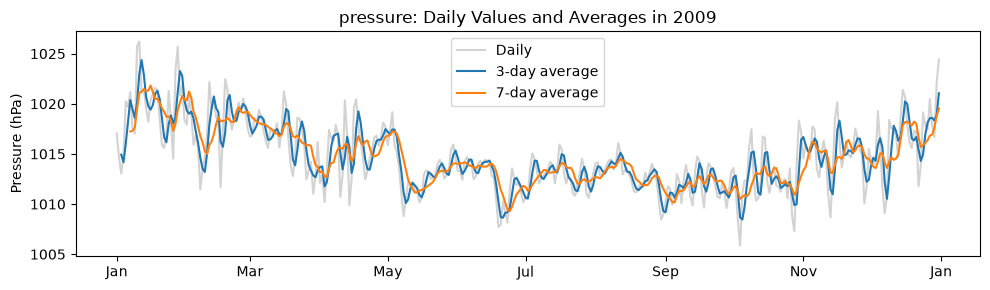

In [98]:
view = weather.loc["2009"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(view.index, view["pressure"], color="lightgray", label="Daily")
ax.plot(view.index, view["pressure_3day"], label="3-day average")
ax.plot(view.index, view["pressure_7day"], label="7-day average")
ax.set_ylabel("Pressure (hPa)")
ax.set_title("pressure: Daily Values and Averages in 2009")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
fig.tight_layout()

## 14. Try nearby grid points

Maybe the weather around Irvine helps too. I take the average of the nine points in a 3 by 3 square, including the Irvine point. I do this for today's temperature and precipitation and add the two averages to the table.

These averages are across nearby places on the same day. Some points may be over the ocean; I have not checked that yet.

In [99]:
temp_nearby = temp_grid.sel(latitude=slice(34.0, 33.5), longitude=slice(-118.0, -117.5))
tp_nearby = tp_grid.sel(latitude=slice(34.0, 33.5), longitude=slice(-118.0, -117.5))
assert temp_nearby.sizes["latitude"] == 3 and temp_nearby.sizes["longitude"] == 3
weather["nearby_temp"] = temp_nearby.mean(["latitude", "longitude"]).compute(scheduler="single-threaded").to_series()
weather["nearby_tp"] = tp_nearby.mean(["latitude", "longitude"]).compute(scheduler="single-threaded").to_series()
print("Nearby latitudes:", temp_nearby.latitude.values)
print("Nearby longitudes:", temp_nearby.longitude.values)
spatial_features = all_features + ["nearby_temp", "nearby_tp"]

Nearby latitudes: [34.   33.75 33.5 ]
Nearby longitudes: [-118.   -117.75 -117.5 ]


### Compare the same days

I use the same validation dates for each model. I also check that the real answers used for training would already be known when I start predicting. This becomes especially important when I predict two or three days ahead.

The functions below collect predictions and calculate scores. For the overall MAE and RMSE, I use all the daily errors from the three rounds together.

In [100]:
periods = [("2010-01-01", "2010-03-01"),
           ("2010-03-01", "2010-05-01"),
           ("2010-05-01", "2010-07-01")]

def regression_scores(predictions):
    rows = []
    for name, part in predictions.groupby("model", sort=False):
        errors = part["predicted"] - part["actual"]
        rows.append({"Model": name, "Days": len(part),
                     "MAE": errors.abs().mean(),
                     "RMSE": np.sqrt((errors ** 2).mean())})
    return pd.DataFrame(rows)

def save_predictions(parts, name, valid, prediction):
    parts.append(pd.DataFrame({"model": name, "date": valid["target_date"].values,
                               "actual": valid["target"].values,
                               "predicted": np.asarray(prediction)}))

## 15. Compare models for tomorrow's temperature

I compare persistence, temperature with its averages, all five weather variables with their averages, and the model with nearby points.

I also try predicting how much temperature will change. The answer for training is tomorrow's temperature minus today's. After predicting the change, I add today's temperature back. I want to see whether this works better than predicting tomorrow's temperature directly.

Finally, I try a small neural network with one hidden layer of 8 units and ReLU. I use the training data to scale the inputs and the temperature answers. I keep the same settings in all three rounds, including the random seed, so I can repeat the experiment. This is one small network to try, rather than a search through many different networks. I used the [scikit-learn guide](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) for this part.

In [101]:
temp_model = weather.copy()
temp_model["target"] = weather["temp"].shift(-1)
temp_model["target_date"] = weather.index + pd.Timedelta(days=1)
temp_model = temp_model.dropna().copy()
temp_parts = []
temp_checks = []

In [102]:
# Refit the models on earlier dates in each round.
for start, end in periods:
    first_forecast_day = pd.Timestamp(start) - pd.Timedelta(days=1)
    train = temp_model[temp_model["target_date"] <= first_forecast_day].copy()
    valid = temp_model[(temp_model["target_date"] >= start) &
                           (temp_model["target_date"] < end)].copy()
    assert train["target_date"].max() <= valid.index.min()
    save_predictions(temp_parts, "Persistence", valid, valid["temp"])

    for name, inputs in [("Own rolling averages", temp_features),
                         ("All weather and averages", all_features),
                         ("Add nearby means", spatial_features)]:
        model = LinearRegression()
        model.fit(train[inputs], train["target"])
        prediction = model.predict(valid[inputs])
        save_predictions(temp_parts, name, valid, prediction)

    absolute_model = LinearRegression().fit(train[all_features], train["target"])
    change_model = LinearRegression()
    change_model.fit(train[all_features], train["target"] - train["temp"])
    change_prediction = change_model.predict(valid[all_features]) + valid["temp"].values
    largest_difference = np.abs(change_prediction - absolute_model.predict(valid[all_features])).max()
    temp_checks.append({"Period": start[:7], "Train": len(train), "Validation": len(valid),
                           "Absolute/change maximum difference": largest_difference})
    save_predictions(temp_parts, "Predict the change", valid, change_prediction)

    x_scaler = StandardScaler().fit(train[all_features])
    y_scaler = StandardScaler().fit(train[["target"]])
    network = MLPRegressor(hidden_layer_sizes=(8,), activation="relu", solver="lbfgs",
                           alpha=0.1, max_iter=10000, max_fun=150000, random_state=42)
    network.fit(x_scaler.transform(train[all_features]),
                y_scaler.transform(train[["target"]]).ravel())
    print("Network round", start[:7], "iterations:", network.n_iter_, "training loss:", network.loss_)
    scaled_prediction = network.predict(x_scaler.transform(valid[all_features]))
    nn_prediction = y_scaler.inverse_transform(scaled_prediction.reshape(-1, 1)).ravel()
    save_predictions(temp_parts, "Small neural network", valid, nn_prediction)

temp_predictions = pd.concat(temp_parts, ignore_index=True)
temp_scores = regression_scores(temp_predictions)
print(pd.DataFrame(temp_checks).to_string(index=False))
temp_scores.round(5)

Network round 2010-01 iterations: 966 training loss: 0.015219355996127332


Network round 2010-03 iterations: 974 training loss: 0.016130708349438822


Network round 2010-05 iterations: 860 training loss: 0.018791262289456125
 Period  Train  Validation  Absolute/change maximum difference
2010-01    358          59                        8.526513e-14
2010-03    417          61                        5.684342e-14
2010-05    478          61                        3.552714e-14


,Model,Days,MAE,RMSE
0,Persistence,181,0.90099,1.14785
1,Own rolling averages,181,0.82281,1.07464
2,All weather and averages,181,0.75698,0.97745
3,Add nearby means,181,0.74204,0.95418
4,Predict the change,181,0.75698,0.97745
5,Small neural network,181,1.14082,1.79019


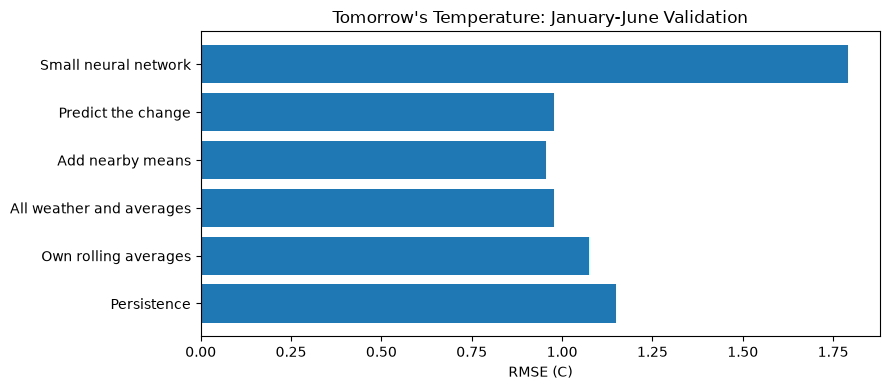

In [103]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(temp_scores["Model"], temp_scores["RMSE"])
ax.set_xlabel("RMSE (C)")
ax.set_title("Tomorrow's Temperature: January-June Validation")
fig.tight_layout()

### What I notice about temperature

Using all five variables and their averages lowers MAE from 0.823 to 0.757 C. Adding the nearby averages lowers it again to 0.742 C. All these scores use the same 181 validation days.

Predicting the temperature change gives the same answers as predicting tomorrow's temperature directly, apart from tiny rounding differences. Today's temperature is already an input, so linear regression can account for the subtraction by changing its slope for that input.

The small neural network does worse: MAE is 1.141 C and RMSE is 1.790 C. A more complicated model did not help here. I only tried one setup, so this does not tell me how every neural network would do.

## 16. Predict temperature two and three days ahead

Can the model still help if I predict further ahead? I train one model for tomorrow, another for two days later, and another for three days later. All three use today's weather and the same 3-day and 7-day averages. For example, the 3-day model predicts three days ahead straight from today's data.

For persistence, I keep using today's temperature as the prediction, whether I am predicting one, two, or three days ahead.

I also check the training dates. For example, if I predict January 1 at the end of December 29, I can only train using answers known by December 29. December 30 and 31 have not happened yet, so their real temperatures cannot be used for training.

I check all three models on the same 181 days from January to June 2010.

In [104]:
future_parts = []
future_counts = []
for target in ["temp"]:
    for horizon in [1, 2, 3]:
        data = weather.copy()
        data["target"] = weather[target].shift(-horizon)
        data["target_date"] = weather.index + pd.Timedelta(days=horizon)
        data = data.dropna().copy()
        for start, end in periods:
            first_forecast_day = pd.Timestamp(start) - pd.Timedelta(days=horizon)
            train = data[data["target_date"] <= first_forecast_day]
            valid = data[(data["target_date"] >= start) & (data["target_date"] < end)]
            assert train["target_date"].max() <= valid.index.min()
            model = LinearRegression().fit(train[all_features], train["target"])
            prediction = model.predict(valid[all_features])
            if target == "tp":
                prediction = np.maximum(prediction, 0)
            parts = []
            save_predictions(parts, "Persistence", valid, valid[target])
            save_predictions(parts, "Linear regression", valid, prediction)
            part = pd.concat(parts, ignore_index=True)
            part["Target"] = target
            part["Horizon"] = horizon
            future_parts.append(part)
            future_counts.append({"Target": target, "Horizon": horizon, "Round": start[:7],
                                  "Train": len(train), "Validation": len(valid),
                                  "Last training target": train["target_date"].max(),
                                  "First forecast date": valid.index.min()})
future_predictions = pd.concat(future_parts, ignore_index=True)
future_rows = []
for (target, horizon), part in future_predictions.groupby(["Target", "Horizon"]):
    scores = regression_scores(part)
    scores["Target"] = target
    scores["Days ahead"] = horizon
    future_rows.append(scores)
future_scores = pd.concat(future_rows, ignore_index=True)
future_scores[["Target", "Days ahead", "Model", "Days", "MAE", "RMSE"]].round(5)

,Target,Days ahead,Model,Days,MAE,RMSE
0,temp,1,Persistence,181,0.90099,1.14785
1,temp,1,Linear regression,181,0.75698,0.97745
2,temp,2,Persistence,181,1.42201,1.81154
3,temp,2,Linear regression,181,1.29191,1.65704
4,temp,3,Persistence,181,1.74340,2.18134
5,temp,3,Linear regression,181,1.52302,1.94083


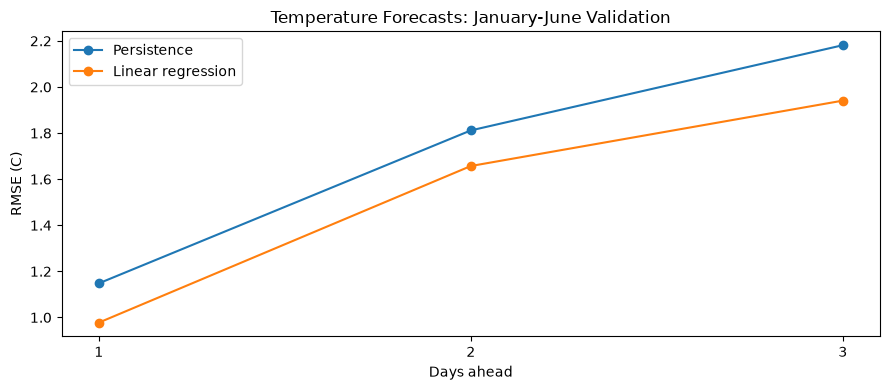

In [105]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in ["Persistence", "Linear regression"]:
    part = future_scores[future_scores["Model"] == name]
    ax.plot(part["Days ahead"], part["RMSE"], marker="o", label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Days ahead")
ax.set_ylabel("RMSE (C)")
ax.set_title("Temperature Forecasts: January-June Validation")
ax.legend()
fig.tight_layout()

### What happened when I predicted further ahead?

Linear regression has a temperature RMSE of 0.977 C for tomorrow, 1.657 C for two days ahead, and 1.941 C for three days ahead. It beats persistence at all three distances on these validation dates.

So I was able to make two- and three-day predictions, but the errors grew as I looked further ahead.

## 17. Predict hot days

Here I try predicting whether tomorrow will be hot. I use the assignment's rule: a daily average temperature above the 75th percentile of the training temperatures. This cutoff separates the warmest quarter of the training days from the rest. It is a definition for this project, not a heat warning.

I calculate the cutoff from training data and keep it the same during that validation round. I calculate it again when I add more training months.

I compare four choices: always say not hot, copy today's hot/not-hot answer, use the linear temperature prediction to decide, and try logistic regression. The two trained models use the same weather inputs. Logistic regression says hot when its probability is at least 0.5.

I check precision and recall, and count how many hot days each model actually finds.

In [106]:
heat_parts = []
heat_thresholds = []
for start, end in periods:
    train = temp_model[temp_model["target_date"] < start].copy()
    valid = temp_model[(temp_model["target_date"] >= start) & (temp_model["target_date"] < end)].copy()
    threshold = train["target"].quantile(0.75)
    y_train = (train["target"] > threshold).astype(int)
    actual = (valid["target"] > threshold).astype(int)
    assert y_train.nunique() == 2
    heat_thresholds.append({"Period": start[:7], "Threshold (C)": threshold,
                            "Training hot days": int(y_train.sum()),
                            "Validation hot days": int(actual.sum()), "Validation days": len(valid)})
    scaler = StandardScaler().fit(train[all_features])
    classifier = LogisticRegression(max_iter=1000)
    classifier.fit(scaler.transform(train[all_features]), y_train)
    linear = LinearRegression().fit(train[all_features], train["target"])
    guesses = {"Always not hot": np.zeros(len(valid), dtype=int),
               "Persistence": (valid["temp"] > threshold).astype(int),
               "Threshold linear prediction": (linear.predict(valid[all_features]) > threshold).astype(int),
               "Logistic regression": classifier.predict(scaler.transform(valid[all_features]))}
    for name, predicted in guesses.items():
        heat_parts.append(pd.DataFrame({"model": name, "date": valid["target_date"].values,
                                        "actual": actual.values, "predicted": np.asarray(predicted)}))
heat_predictions = pd.concat(heat_parts, ignore_index=True)
pd.DataFrame(heat_thresholds).round(3)

,Period,Threshold (C),Training hot days,Validation hot days,Validation days
0,2010-01,19.926,90,0,59
1,2010-03,19.326,104,0,61
2,2010-05,18.740,120,5,61


In [107]:
heat_rows = []
for name, part in heat_predictions.groupby("model", sort=False):
    actual, predicted = part["actual"], part["predicted"]
    heat_rows.append({"Model": name, "Accuracy": accuracy_score(actual, predicted),
                      "Precision": precision_score(actual, predicted, zero_division=0),
                      "Recall": recall_score(actual, predicted, zero_division=0),
                      "TP": int(((actual == 1) & (predicted == 1)).sum()),
                      "FP": int(((actual == 0) & (predicted == 1)).sum()),
                      "FN": int(((actual == 1) & (predicted == 0)).sum())})
heat_scores = pd.DataFrame(heat_rows)
heat_scores.round(4)

,Model,Accuracy,Precision,Recall,TP,FP,FN
0,Always not hot,0.9724,0.0000,0.0,0,0,5
1,Persistence,0.9669,0.4000,0.4,2,3,3
2,Threshold linear prediction,0.9613,0.3333,0.4,2,4,3
3,Logistic regression,0.9779,1.0000,0.2,1,0,4


### There are very few hot days to check

The cutoffs are 19.93, 19.33, and 18.74 C in the three rounds. The first two rounds have no hot days by this rule, and the third has only five.

Logistic regression gets 97.8% accuracy but finds only one of those five days. Persistence finds two, so its recall is 40%, compared with 20% for logistic regression. Logistic has no false alarms here, while persistence has three. Even always saying not hot gets 97.2% accuracy.

The high accuracy does not mean the model is good at finding hot days. I keep the original rule and report how many days it misses. More data, especially a longer period including summer, would make this easier to check.

If a model never predicts a hot day, there is no way to calculate its precision. The table shows 0 in that case. I need to look at the counts as well as accuracy, especially when most validation days are not hot.

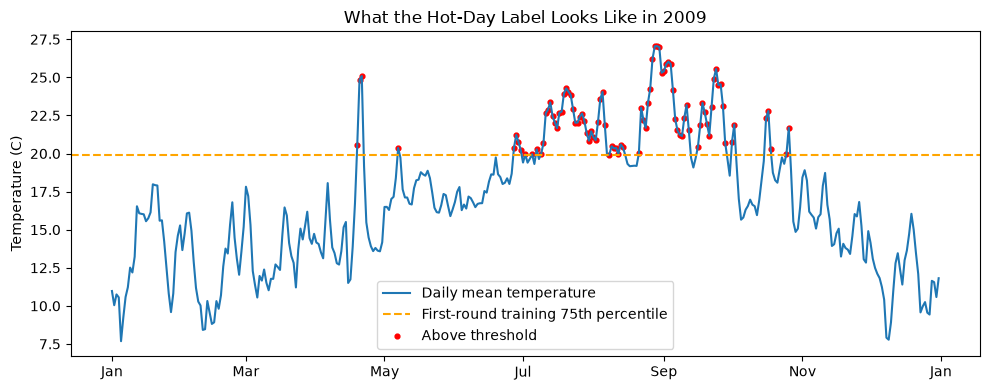

In [108]:
fig, ax = plt.subplots(figsize=(10, 4))
heat_view = weather.loc["2009", "temp"]
ax.plot(heat_view.index, heat_view, label="Daily mean temperature")
reference = temp_model.loc[temp_model["target_date"] < "2010-01-01", "target"].quantile(0.75)
ax.axhline(reference, color="orange", linestyle="--", label="First-round training 75th percentile")
ax.scatter(heat_view.index[heat_view > reference], heat_view[heat_view > reference], color="red", s=12, label="Above threshold")
ax.set_ylabel("Temperature (C)")
ax.set_title("What the Hot-Day Label Looks Like in 2009")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend()
fig.tight_layout()

## 18. What I found

Weather averages and nearby points helped predict temperature in these comparisons. Predicting the change gave the same linear predictions, and the small neural network did worse. The two- and three-day models still beat persistence, but their errors were bigger than the one-day model's.

For hot days, almost 98% accuracy looked good at first, but the model found only one of five hot days. I need more hot days to see whether this approach is useful.

Notebook 06 checks the earlier chosen models on July-December. It does not check every model tried here. Since I have already looked at that period, I would need unused dates to give these extra models a new test.

In [109]:
OUTPUT_DIR = PROJECT_DIR.parent / "Project1_WeatherPrediction_materials" / "results" / "model_comparisons"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
temp_scores.to_csv(OUTPUT_DIR / "temperature.csv", index=False)
temp_predictions.to_csv(OUTPUT_DIR / "temperature_predictions.csv", index=False)
heat_scores.to_csv(OUTPUT_DIR / "extreme_heat.csv", index=False)
heat_predictions.to_csv(OUTPUT_DIR / "heat_predictions.csv", index=False)
pd.DataFrame(heat_thresholds).to_csv(OUTPUT_DIR / "heat_thresholds.csv", index=False)
future_scores.to_csv(OUTPUT_DIR / "temperature_horizons.csv", index=False)
future_predictions.to_csv(OUTPUT_DIR / "temperature_horizon_predictions.csv", index=False)
pd.DataFrame(future_counts).to_csv(OUTPUT_DIR / "temperature_forecast_date_checks.csv", index=False)

round_tables = []
for start, end in periods:
    part = temp_predictions[(temp_predictions["date"] >= start) & (temp_predictions["date"] < end)]
    scores = regression_scores(part)
    scores["Period"] = start[:7]
    round_tables.append(scores)
pd.concat(round_tables, ignore_index=True).to_csv(OUTPUT_DIR / "temperature_by_round.csv", index=False)
print("Saved the comparison tables.")

Saved the comparison tables.
